# FIREGUARD ID — 01: Data Audit & Exploratory Data Analysis (EDA)

            **Scope & Guardrails (`docs/AGENT_GUARDRAILS.md`, `docs/DATA_SOURCE_REGISTER.md`):**
            - Verified local sources only: **NASA FIRMS VIIRS NOAA-20 (`JPSS-1`, `SRC-01`)** for `2021-01-01` to `2025-12-31`, and **GADM 4.1 Riau (`IDN.24_1`, `SRC-02`)**.
            - **Hotspots != Unique Fire Incidents:** VIIRS 375m records are active thermal anomalies across satellite overpasses.
            - **Confidence is QA Metadata Only:** `confidence` (`l`, `n`, `h`) is never entered into clustering features.
            - **Zero Detections != Zero Risk:** Cloud/canopy/overpass gaps can suppress detections. Unacquired datasets (`S-NPP`, `ERA5-Land`, `CHIRPS`, `MODIS`, `DEMNAS`, `OSM`) are never fabricated.


In [1]:
import os
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))
os.environ.setdefault("MPLCONFIGDIR", str(REPO_ROOT / ".mplconfig"))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.utils import load_yaml, resolve_path

proj_cfg = load_yaml("config/project.yaml", repo_root=REPO_ROOT)
print(f"Project: {proj_cfg['project']['name']} v{proj_cfg['project']['version']} | Pilot: {proj_cfg['project']['pilot_region']}")

from src.data.ingestion import ensure_riau_boundary, load_raw_viirs_jpss1
from src.data.quality import compute_temporal_coverage, run_viirs_quality_audit
from src.data_loader import load_boundary, load_hotspots, load_grid_profiles
from src.geospatial.geometry import geodesic_area_km2, load_boundary_geometry
from src.eda_pipeline import run_phase4_eda_pipeline


Project: FIREGUARD-ID v2.0.0 | Pilot: Riau Province, Indonesia


## 1. Boundary Geometry & Verified Data Quality Audit


In [2]:
processed_dir = resolve_path(proj_cfg["paths"]["processed_dir"], repo_root=REPO_ROOT)
reports_dir = resolve_path(proj_cfg["paths"]["reports_dir"], repo_root=REPO_ROOT)

riau_geom, riau_props = load_boundary_geometry(processed_dir / "riau_boundary.geojson")
area_km2 = geodesic_area_km2(riau_geom)
df_hot = load_hotspots(repo_root=REPO_ROOT)

dq_summary = json.loads((reports_dir / "data_quality" / "data_quality_summary.json").read_text(encoding="utf-8"))
qa = dq_summary["quality_audit"]
print(f"Riau GADM 4.1 Area (WGS84 geodesic): {area_km2:,.2f} km2 | Bounds: {[round(x, 4) for x in riau_geom.bounds]}")
print(f"Raw Indonesia VIIRS rows: {qa['raw_record_count']:,} -> Riau clipped detections: {len(df_hot):,}")
print(f"Nulls in clipped dataset: {int(df_hot.isna().sum().sum())} | Negative FRP: {qa['physical_checks_clipped']['negative_frp']}")
print(f"QA Confidence distribution (excluded from clustering): {qa['confidence_distribution_qa_only']['clipped']}")


Riau GADM 4.1 Area (WGS84 geodesic): 89,874.50 km2 | Bounds: [100.0249, -1.1223, 103.8146, 2.9191]
Raw Indonesia VIIRS rows: 595,676 -> Riau clipped detections: 15,510
Nulls in clipped dataset: 0 | Negative FRP: 0
QA Confidence distribution (excluded from clustering): {'n': 14740, 'l': 409, 'h': 361}


## 2. Temporal Variability & Bimodal Dry-Season Cycle (2021–2025)


,detections,median_frp,p90_frp
year,,,
2021,3081,2.950,10.71
2022,1715,2.850,11.07
2023,3308,2.900,14.16
2024,3402,3.365,12.33
2025,4004,3.650,17.23


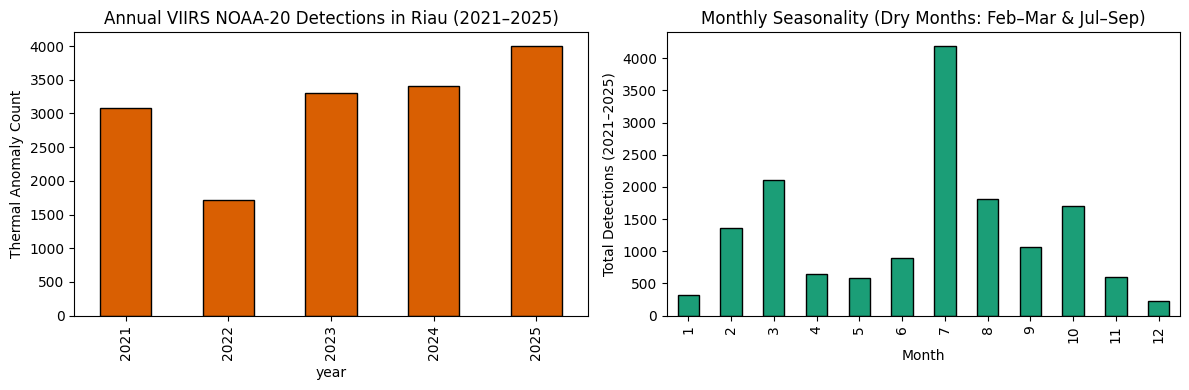

In [3]:
df_hot["acq_dt"] = pd.to_datetime(df_hot["acq_date"])
df_hot["year"] = df_hot["acq_dt"].dt.year
df_hot["month"] = df_hot["acq_dt"].dt.month

annual = df_hot.groupby("year").agg(detections=("frp", "size"), median_frp=("frp", "median"), p90_frp=("frp", lambda s: np.percentile(s, 90)))
monthly = df_hot.groupby("month").size()

display(annual)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
annual["detections"].plot(kind="bar", ax=axes[0], color="#d95f02", edgecolor="black")
axes[0].set_title("Annual VIIRS NOAA-20 Detections in Riau (2021–2025)")
axes[0].set_ylabel("Thermal Anomaly Count")

monthly.plot(kind="bar", ax=axes[1], color="#1b9e77", edgecolor="black")
axes[1].set_title("Monthly Seasonality (Dry Months: Feb–Mar & Jul–Sep)")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Total Detections (2021–2025)")
plt.tight_layout()
plt.show()


## 3. Grid-Level Skewness, Zero-Detection Cells & Spatial Autocorrelation


In [4]:
df_grid = load_grid_profiles(repo_root=REPO_ROOT)
n_zero = int(df_grid["has_zero_detections"].sum())
print(f"Grid cells: {len(df_grid)} | Zero-detection cells: {n_zero} ({100*n_zero/len(df_grid):.1f}%)")
print(f"Total assigned hotspots: {int(df_grid['hotspot_count'].sum()):,}")
print(df_grid[["hotspot_density_km2", "fire_days", "active_years_count", "frp_total_density_mw_km2"]].describe().round(4))


Grid cells: 853 | Zero-detection cells: 249 (29.2%)
Total assigned hotspots: 15,510
       hotspot_density_km2  fire_days  active_years_count  \
count             853.0000   853.0000            853.0000   
mean                0.1789     8.5287              2.0164   
std                 0.4650    25.9752              1.7702   
min                 0.0000     0.0000              0.0000   
25%                 0.0000     0.0000              0.0000   
50%                 0.0325     3.0000              2.0000   
75%                 0.1410     9.0000              4.0000   
max                 7.0886   472.0000              5.0000   

       frp_total_density_mw_km2  
count                  853.0000  
mean                     1.0840  
std                      3.1761  
min                      0.0000  
25%                      0.0000  
50%                      0.1183  
75%                      0.5829  
max                     42.1954  
